# H2 — Source Quality × Local Dataset Support



In [1]:
6+6

12

In [2]:
import os
import sys
from pathlib import Path
import pickle
import time

# Set BEFORE importing JAX
os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"] = "false"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import jax
import jax.numpy as jnp


# ------------------------------------------------------------
# Find GTA repo root
# ------------------------------------------------------------

cwd = Path.cwd().resolve()

REPO = None

for candidate in [cwd, *cwd.parents]:
    p = candidate / "data" / "halfcheetah-medium-v2.pkl"

    if p.exists():
        REPO = candidate
        break

assert REPO is not None, "Could not find GTA repository root."

DATASET_PATH = REPO / "data" / "halfcheetah-medium-v2.pkl"


# ------------------------------------------------------------
# H2 config
# ------------------------------------------------------------

H = 31
GAMMA = 0.99
TERMINAL_PENALTY = 100.0
REWARD_SCALE = 0.01

STATE_DIM = 17
ACTION_DIM = 6
SA_DIM = STATE_DIM + ACTION_DIM

PILOT_SOURCES = 500
K_SUPPORT = 20
QUERY_BATCH = 32

SEED = 42
rng = np.random.default_rng(SEED)


print("Python :", sys.executable)
print("Repo   :", REPO)
print("Dataset:", DATASET_PATH)

print()
print("JAX version :", jax.__version__)
print("Backend     :", jax.default_backend())
print("Devices     :", jax.devices())

assert DATASET_PATH.exists()
assert jax.default_backend() == "gpu"

print("\nH2 SETUP READY")

Python : /home/ic43980/miniconda3/envs/gta-jax/bin/python
Repo   : /mnt/storage/ic43980/gta_reproduction/GTA
Dataset: /mnt/storage/ic43980/gta_reproduction/GTA/data/halfcheetah-medium-v2.pkl

JAX version : 0.11.2
Backend     : gpu
Devices     : [CudaDevice(id=0)]

H2 SETUP READY


In [3]:
with open(DATASET_PATH, "rb") as f:
    episodes = pickle.load(f)

episode_lengths = np.asarray(
    [len(ep["observations"]) for ep in episodes],
    dtype=np.int32,
)

num_transitions = int(
    episode_lengths.sum()
)

num_sources = int(
    np.maximum(
        episode_lengths - H + 1,
        0,
    ).sum()
)

print("Episodes            :", len(episodes))
print("Transitions         :", num_transitions)
print("H=31 source windows :", num_sources)
print(
    "Episode length range:",
    episode_lengths.min(),
    "to",
    episode_lengths.max(),
)

assert num_sources == 970_000

print("\nSOURCE COUNT MATCHES GTA")

Episodes            : 1000
Transitions         : 1000000
H=31 source windows : 970000
Episode length range: 1000 to 1000

SOURCE COUNT MATCHES GTA


In [4]:
def discounted_cumsum(x, gamma):
    x = np.asarray(
        x,
        dtype=np.float32,
    )

    out = np.zeros_like(
        x,
        dtype=np.float32,
    )

    out[-1] = x[-1]

    for t in range(
        len(x) - 2,
        -1,
        -1,
    ):
        out[t] = (
            x[t]
            + gamma * out[t + 1]
        )

    return out


rows = []
source_id = 0


for episode_id, ep in enumerate(episodes):

    rewards = np.asarray(
        ep["rewards"],
        dtype=np.float32,
    )

    terminals = np.asarray(
        ep["terminals"]
    ).astype(bool)

    if len(rewards) < H:
        continue

    # Match GTA trajectory dataset.
    gta_rewards = rewards.copy()

    if terminals.any():

        assert terminals[-1]
        assert not terminals[:-1].any()

        gta_rewards[-1] -= TERMINAL_PENALTY

    gta_returns = discounted_cumsum(
        gta_rewards,
        GAMMA,
    )

    n_windows = (
        len(rewards)
        - H
        + 1
    )

    for start_idx in range(n_windows):

        end_idx = (
            start_idx
            + H
            - 1
        )

        # Exact GTA conditioning return
        gta_return = float(
            gta_returns[start_idx]
        )

        # Also retain H=31-only discounted return
        r31 = gta_rewards[
            start_idx:
            start_idx + H
        ]

        segment_return = float(
            np.sum(
                r31
                * GAMMA
                ** np.arange(
                    H,
                    dtype=np.float32,
                )
            )
        )

        rows.append(
            (
                source_id,
                episode_id,
                start_idx,
                end_idx,
                gta_return,
                segment_return,
            )
        )

        source_id += 1


catalog = pd.DataFrame(
    rows,
    columns=[
        "source_id",
        "episode_id",
        "start_idx",
        "end_idx",
        "gta_return",
        "segment_return_h31",
    ],
)

del rows


# Dataset-relative source quality percentile
catalog["q_i"] = (
    catalog["gta_return"]
    .rank(
        method="average",
        pct=True,
    )
)


print("Catalog:", catalog.shape)

display(catalog.head())

assert len(catalog) == 970_000
assert catalog["source_id"].is_unique

Catalog: (970000, 7)


,source_id,episode_id,start_idx,end_idx,gta_return,segment_return_h31,q_i
0,0,0,0,30,348.745575,47.408020,0.108051
1,1,0,1,31,352.470337,50.332787,0.111153
2,2,0,2,32,357.240906,54.855312,0.115426
3,3,0,3,33,361.547150,58.695274,0.119466
4,4,0,4,34,364.928253,61.641174,0.122729


,gta_return,segment_return_h31,q_i
count,970000.000000,970000.000000,970000.000000
mean,451.774002,129.275406,0.500001
std,89.256212,24.026588,0.288675
min,-41.761311,-22.532228,0.000001
25%,432.399178,120.687664,0.250001
50%,477.655853,134.139359,0.500001
75%,506.515312,144.126118,0.750000
max,592.928528,185.297684,1.000000


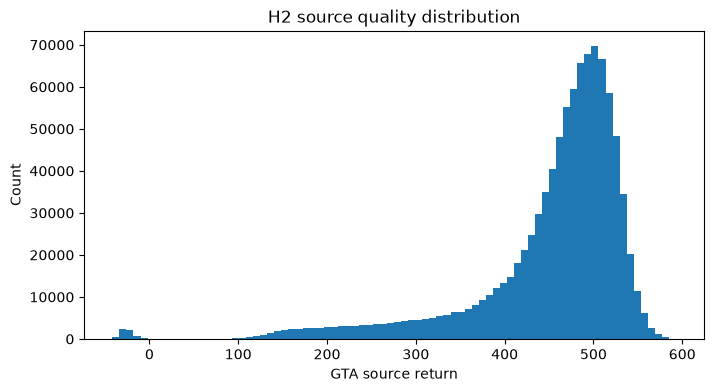

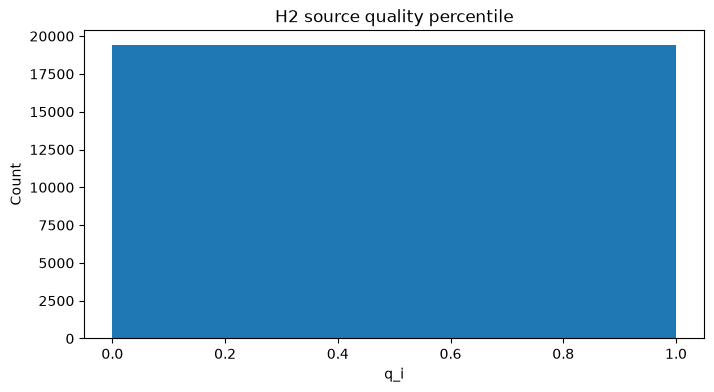

In [5]:
display(
    catalog[
        [
            "gta_return",
            "segment_return_h31",
            "q_i",
        ]
    ].describe()
)


plt.figure(figsize=(8, 4))

plt.hist(
    catalog["gta_return"],
    bins=80,
)

plt.xlabel("GTA source return")
plt.ylabel("Count")
plt.title("H2 source quality distribution")
plt.show()


plt.figure(figsize=(8, 4))

plt.hist(
    catalog["q_i"],
    bins=50,
)

plt.xlabel("q_i")
plt.ylabel("Count")
plt.title("H2 source quality percentile")
plt.show()

In [6]:
sa_parts = []
episode_id_parts = []

for episode_id, ep in enumerate(episodes):

    obs = np.asarray(
        ep["observations"],
        dtype=np.float32,
    )

    actions = np.asarray(
        ep["actions"],
        dtype=np.float32,
    )

    sa_episode = np.concatenate(
        [obs, actions],
        axis=-1,
    )

    sa_parts.append(
        sa_episode
    )

    episode_id_parts.append(
        np.full(
            len(obs),
            episode_id,
            dtype=np.int32,
        )
    )


SA = np.concatenate(
    sa_parts,
    axis=0,
)

transition_episode = np.concatenate(
    episode_id_parts,
    axis=0,
)


assert SA.shape == (
    num_transitions,
    23,
)


# Sample std: denominator N-1
sa_mean = SA.mean(
    axis=0,
    dtype=np.float64,
).astype(np.float32)

sa_std = SA.std(
    axis=0,
    ddof=1,
    dtype=np.float64,
).astype(np.float32)


Z = (
    SA - sa_mean
) / (
    sa_std + 1e-8
)

Z = Z.astype(
    np.float32
)


print("SA :", SA.shape)
print("Z  :", Z.shape)

print(
    "Mean normalized value:",
    float(Z.mean()),
)

print(
    "Mean absolute value:",
    float(np.abs(Z).mean()),
)


np.savez(
    REPO
    / "data"
    / "h2_sa_normalization.npz",

    mean=sa_mean,
    std=sa_std,
)

SA : (1000000, 23)
Z  : (1000000, 23)
Mean normalized value: -1.4605978648773998e-08
Mean absolute value: 0.7823972105979919


In [7]:
sa_parts = []
episode_id_parts = []

for episode_id, ep in enumerate(episodes):

    obs = np.asarray(
        ep["observations"],
        dtype=np.float32,
    )

    actions = np.asarray(
        ep["actions"],
        dtype=np.float32,
    )

    sa_episode = np.concatenate(
        [obs, actions],
        axis=-1,
    )

    sa_parts.append(
        sa_episode
    )

    episode_id_parts.append(
        np.full(
            len(obs),
            episode_id,
            dtype=np.int32,
        )
    )


SA = np.concatenate(
    sa_parts,
    axis=0,
)

transition_episode = np.concatenate(
    episode_id_parts,
    axis=0,
)


assert SA.shape == (
    num_transitions,
    23,
)


# Sample std: denominator N-1
sa_mean = SA.mean(
    axis=0,
    dtype=np.float64,
).astype(np.float32)

sa_std = SA.std(
    axis=0,
    ddof=1,
    dtype=np.float64,
).astype(np.float32)


Z = (
    SA - sa_mean
) / (
    sa_std + 1e-8
)

Z = Z.astype(
    np.float32
)


print("SA :", SA.shape)
print("Z  :", Z.shape)

print(
    "Mean normalized value:",
    float(Z.mean()),
)

print(
    "Mean absolute value:",
    float(np.abs(Z).mean()),
)


np.savez(
    REPO
    / "data"
    / "h2_sa_normalization.npz",

    mean=sa_mean,
    std=sa_std,
)

SA : (1000000, 23)
Z  : (1000000, 23)
Mean normalized value: -1.4605978648773998e-08
Mean absolute value: 0.7823972105979919


In [9]:
pilot_parts = []

quality_bins = np.linspace(
    0.0,
    1.0,
    11,
)

per_bin = (
    PILOT_SOURCES // 10
)


for b in range(10):

    lo = quality_bins[b]
    hi = quality_bins[b + 1]

    if b == 9:
        group = catalog[
            (catalog["q_i"] >= lo)
            &
            (catalog["q_i"] <= hi)
        ]
    else:
        group = catalog[
            (catalog["q_i"] >= lo)
            &
            (catalog["q_i"] < hi)
        ]

    n = min(
        per_bin,
        len(group),
    )

    pilot_parts.append(
        group.sample(
            n=n,
            random_state=SEED + b,
        )
    )


pilot = pd.concat(
    pilot_parts,
    ignore_index=True,
)

pilot = (
    pilot
    .sort_values("source_id")
    .reset_index(drop=True)
)


print(
    "Pilot sources:",
    len(pilot),
)

display(
    pilot.head()
)

Pilot sources: 500


,source_id,episode_id,start_idx,end_idx,gta_return,segment_return_h31,q_i
0,140,0,140,170,466.710175,124.065292,0.419539
1,3035,3,125,155,518.468811,145.442993,0.849639
2,4140,4,260,290,467.051727,112.452080,0.421851
3,9288,9,558,588,504.575256,137.541397,0.732264
4,12176,12,536,566,451.202454,130.692932,0.328315


In [10]:
episode_offsets = np.zeros(
    len(episodes),
    dtype=np.int64,
)

episode_offsets[1:] = np.cumsum(
    episode_lengths[:-1],
    dtype=np.int64,
)


query_ids = []


for row in pilot.itertuples():

    global_start = (
        episode_offsets[
            row.episode_id
        ]
        + row.start_idx
    )

    ids = (
        global_start
        + np.arange(
            H,
            dtype=np.int64,
        )
    )

    query_ids.append(ids)


query_ids = np.stack(
    query_ids
)


print(
    "query_ids:",
    query_ids.shape,
)

assert query_ids.shape == (
    len(pilot),
    H,
)

query_ids: (500, 31)


In [11]:
Z_gpu = jax.device_put(
    jnp.asarray(Z)
)

episode_gpu = jax.device_put(
    jnp.asarray(
        transition_episode
    )
)


reference_norm = jnp.sum(
    Z_gpu * Z_gpu,
    axis=1,
)


print(
    "Reference:",
    Z_gpu.shape,
)

print(
    "Device:",
    Z_gpu.device,
)

: 

In [ ]:
@jax.jit
def kth_neighbor_distance(
    query,
    query_episode,
):
    """
    query:
        [B, 23]

    query_episode:
        [B]
    """

    query_norm = jnp.sum(
        query * query,
        axis=1,
        keepdims=True,
    )

    d2 = (
        query_norm
        + reference_norm[None, :]
        - 2.0 * query @ Z_gpu.T
    )

    d2 = jnp.maximum(
        d2,
        0.0,
    )

    # Exclude WHOLE source episode
    same_episode = (
        query_episode[:, None]
        == episode_gpu[None, :]
    )

    d2 = jnp.where(
        same_episode,
        jnp.inf,
        d2,
    )

    # Need smallest K values.
    # top_k finds largest, so negate.
    vals, _ = jax.lax.top_k(
        -d2,
        K_SUPPORT,
    )

    kth_squared = (
        -vals[:, -1]
    )

    return jnp.sqrt(
        kth_squared
    )

In [ ]:
support_matrix = np.zeros(
    (
        len(pilot),
        H,
    ),
    dtype=np.float32,
)


all_requests = []


for source_pos in range(
    len(pilot)
):

    for t in range(H):

        global_id = query_ids[
            source_pos,
            t,
        ]

        all_requests.append(
            (
                source_pos,
                t,
                global_id,
            )
        )


start_time = time.time()


for start in range(
    0,
    len(all_requests),
    QUERY_BATCH,
):

    batch_requests = (
        all_requests[
            start:
            start + QUERY_BATCH
        ]
    )

    ids = np.asarray(
        [
            x[2]
            for x in batch_requests
        ],
        dtype=np.int64,
    )

    q = Z[ids]

    q_episode = (
        transition_episode[ids]
    )


    real_batch = len(ids)


    # Pad final batch
    if real_batch < QUERY_BATCH:

        pad = (
            QUERY_BATCH
            - real_batch
        )

        q = np.pad(
            q,
            (
                (0, pad),
                (0, 0),
            ),
        )

        q_episode = np.pad(
            q_episode,
            (0, pad),
            constant_values=-1,
        )


    distances = (
        kth_neighbor_distance(
            jax.device_put(
                jnp.asarray(q)
            ),
            jax.device_put(
                jnp.asarray(
                    q_episode
                )
            ),
        )
    )

    distances = np.asarray(
        jax.device_get(
            distances
        )
    )[:real_batch]


    for j, d in enumerate(
        distances
    ):

        source_pos, t, _ = (
            batch_requests[j]
        )

        support_matrix[
            source_pos,
            t,
        ] = d


    done = min(
        start + QUERY_BATCH,
        len(all_requests),
    )


    if (
        start == 0
        or done % 1000 < QUERY_BATCH
        or done == len(all_requests)
    ):

        elapsed = (
            time.time()
            - start_time
        )

        rate = (
            done
            / elapsed
        )

        remaining = (
            len(all_requests)
            - done
        )

        eta = (
            remaining
            / max(
                rate,
                1e-8,
            )
        )

        print(
            f"\r{done:,}/{len(all_requests):,}"
            f" | {rate:.1f} queries/s"
            f" | ETA {eta/60:.1f} min",
            end="",
        )


print("\n")

assert np.isfinite(
    support_matrix
).all()

print(
    "SUPPORT CALCULATION COMPLETE"
)

In [1]:
%pip install -q --no-cache-dir faiss-cpu

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import pickle
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import faiss


# Find GTA repo automatically
cwd = Path.cwd().resolve()

REPO = None

for candidate in [cwd, *cwd.parents]:
    p = candidate / "data" / "halfcheetah-medium-v2.pkl"

    if p.exists():
        REPO = candidate
        break

assert REPO is not None, "Could not find GTA repo."

DATASET_PATH = (
    REPO
    / "data"
    / "halfcheetah-medium-v2.pkl"
)


H = 31
GAMMA = 0.99
TERMINAL_PENALTY = 100.0

STATE_DIM = 17
ACTION_DIM = 6
SA_DIM = 23

# Start small/fast.
PILOT_SOURCES = 100

K_SUPPORT = 20
FAISS_BATCH = 64

SEED = 42
rng = np.random.default_rng(SEED)


print("Repo    :", REPO)
print("Dataset :", DATASET_PATH)
print("FAISS   :", faiss.__version__)
print("Exists  :", DATASET_PATH.exists())

assert DATASET_PATH.exists()

print("\nH2 SETUP READY")

Repo    : /mnt/storage/ic43980/gta_reproduction/GTA
Dataset : /mnt/storage/ic43980/gta_reproduction/GTA/data/halfcheetah-medium-v2.pkl
FAISS   : 1.15.1
Exists  : True

H2 SETUP READY


In [3]:
with open(DATASET_PATH, "rb") as f:
    episodes = pickle.load(f)


episode_lengths = np.asarray(
    [
        len(ep["observations"])
        for ep in episodes
    ],
    dtype=np.int32,
)

num_transitions = int(
    episode_lengths.sum()
)

num_sources = int(
    np.maximum(
        episode_lengths - H + 1,
        0,
    ).sum()
)


print("Episodes     :", len(episodes))
print("Transitions  :", num_transitions)
print("H=31 windows :", num_sources)

assert num_sources == 970_000

Episodes     : 1000
Transitions  : 1000000
H=31 windows : 970000


In [4]:
def discounted_cumsum(x, gamma):

    x = np.asarray(
        x,
        dtype=np.float32,
    )

    out = np.zeros_like(x)

    out[-1] = x[-1]

    for t in range(
        len(x) - 2,
        -1,
        -1,
    ):
        out[t] = (
            x[t]
            + gamma * out[t + 1]
        )

    return out


rows = []
source_id = 0


for episode_id, ep in enumerate(episodes):

    rewards = np.asarray(
        ep["rewards"],
        dtype=np.float32,
    )

    terminals = np.asarray(
        ep["terminals"]
    ).astype(bool)

    if len(rewards) < H:
        continue

    # Match GTA preprocessing
    gta_rewards = rewards.copy()

    if terminals.any():

        assert terminals[-1]
        assert not terminals[:-1].any()

        gta_rewards[-1] -= (
            TERMINAL_PENALTY
        )

    gta_returns = discounted_cumsum(
        gta_rewards,
        GAMMA,
    )

    n_windows = (
        len(rewards)
        - H
        + 1
    )

    for start_idx in range(n_windows):

        end_idx = (
            start_idx
            + H
            - 1
        )

        gta_return = float(
            gta_returns[start_idx]
        )

        # Also retain H=31-only return
        r31 = gta_rewards[
            start_idx:
            start_idx + H
        ]

        segment_return = float(
            np.sum(
                r31
                * (
                    GAMMA
                    ** np.arange(
                        H,
                        dtype=np.float32,
                    )
                )
            )
        )

        rows.append(
            (
                source_id,
                episode_id,
                start_idx,
                end_idx,
                gta_return,
                segment_return,
            )
        )

        source_id += 1


catalog = pd.DataFrame(
    rows,
    columns=[
        "source_id",
        "episode_id",
        "start_idx",
        "end_idx",
        "gta_return",
        "segment_return_h31",
    ],
)

del rows


catalog["q_i"] = (
    catalog["gta_return"]
    .rank(
        method="average",
        pct=True,
    )
)


print("Catalog:", catalog.shape)

display(
    catalog.head()
)

assert len(catalog) == 970_000

Catalog: (970000, 7)


,source_id,episode_id,start_idx,end_idx,gta_return,segment_return_h31,q_i
0,0,0,0,30,348.745575,47.408020,0.108051
1,1,0,1,31,352.470337,50.332787,0.111153
2,2,0,2,32,357.240906,54.855312,0.115426
3,3,0,3,33,361.547150,58.695274,0.119466
4,4,0,4,34,364.928253,61.641174,0.122729


In [5]:
sa_parts = []
episode_parts = []


for episode_id, ep in enumerate(episodes):

    obs = np.asarray(
        ep["observations"],
        dtype=np.float32,
    )

    actions = np.asarray(
        ep["actions"],
        dtype=np.float32,
    )

    sa_parts.append(
        np.concatenate(
            [obs, actions],
            axis=-1,
        )
    )

    episode_parts.append(
        np.full(
            len(obs),
            episode_id,
            dtype=np.int32,
        )
    )


SA = np.concatenate(
    sa_parts,
    axis=0,
).astype(np.float32)

transition_episode = np.concatenate(
    episode_parts
)


assert SA.shape == (
    1_000_000,
    23,
)


sa_mean = SA.mean(
    axis=0,
    dtype=np.float64,
).astype(np.float32)

sa_std = SA.std(
    axis=0,
    ddof=1,
    dtype=np.float64,
).astype(np.float32)


Z = (
    (SA - sa_mean)
    / (sa_std + 1e-8)
).astype(np.float32)

Z = np.ascontiguousarray(Z)


print("State-action bank:", Z.shape)

State-action bank: (1000000, 23)


In [6]:
pilot_parts = []

edges = np.linspace(
    0.0,
    1.0,
    11,
)

per_bin = (
    PILOT_SOURCES // 10
)


for b in range(10):

    lo = edges[b]
    hi = edges[b + 1]

    if b == 9:

        group = catalog[
            (catalog["q_i"] >= lo)
            &
            (catalog["q_i"] <= hi)
        ]

    else:

        group = catalog[
            (catalog["q_i"] >= lo)
            &
            (catalog["q_i"] < hi)
        ]

    pilot_parts.append(
        group.sample(
            n=min(
                per_bin,
                len(group),
            ),
            random_state=SEED + b,
        )
    )


pilot = (
    pd.concat(
        pilot_parts,
        ignore_index=True,
    )
    .sort_values("source_id")
    .reset_index(drop=True)
)


print("Pilot sources:", len(pilot))

display(pilot.head())

Pilot sources: 100


,source_id,episode_id,start_idx,end_idx,gta_return,segment_return_h31,q_i
0,19622,20,222,252,518.298950,136.887253,0.848385
1,28896,29,766,796,456.424683,130.594696,0.355740
2,32844,33,834,864,417.354034,155.486298,0.206578
3,41957,43,247,277,554.338196,151.208221,0.990372
4,62006,63,896,926,325.650543,120.261940,0.090359


In [7]:
episode_offsets = np.zeros(
    len(episodes),
    dtype=np.int64,
)

episode_offsets[1:] = np.cumsum(
    episode_lengths[:-1],
    dtype=np.int64,
)


query_ids = []


for row in pilot.itertuples(
    index=False
):

    global_start = (
        episode_offsets[
            row.episode_id
        ]
        + row.start_idx
    )

    ids = (
        global_start
        + np.arange(
            H,
            dtype=np.int64,
        )
    )

    query_ids.append(ids)


query_ids = np.stack(
    query_ids
)


print(
    "Requested transitions:",
    query_ids.size,
)


unique_query_ids, inverse_query = (
    np.unique(
        query_ids.reshape(-1),
        return_inverse=True,
    )
)


print(
    "Unique transitions:",
    len(unique_query_ids),
)

Requested transitions: 3100
Unique transitions: 3100


In [8]:
index = faiss.IndexFlatL2(
    SA_DIM
)

index.add(Z)


max_episode_len = int(
    episode_lengths.max()
)

# At most max_episode_len candidates
# can belong to the source episode.
#
# Therefore this guarantees at least
# K_SUPPORT external-episode neighbors.
SEARCH_K = (
    max_episode_len
    + K_SUPPORT
)


print(
    "FAISS vectors:",
    index.ntotal,
)

print(
    "Search K:",
    SEARCH_K,
)

FAISS vectors: 1000000
Search K: 1020


In [9]:
def compute_support(
    unique_ids,
):

    result = np.empty(
        len(unique_ids),
        dtype=np.float32,
    )

    start_time = time.time()


    for start in range(
        0,
        len(unique_ids),
        FAISS_BATCH,
    ):

        end = min(
            start + FAISS_BATCH,
            len(unique_ids),
        )

        ids = unique_ids[
            start:end
        ]


        queries = np.ascontiguousarray(
            Z[ids],
            dtype=np.float32,
        )


        query_episodes = (
            transition_episode[ids]
        )


        D2, I = index.search(
            queries,
            SEARCH_K,
        )


        for r in range(
            len(ids)
        ):

            candidate_episodes = (
                transition_episode[
                    I[r]
                ]
            )

            valid = (
                candidate_episodes
                != query_episodes[r]
            )

            external_d2 = (
                D2[r][valid]
            )


            assert (
                len(external_d2)
                >= K_SUPPORT
            )


            kth_d2 = (
                external_d2[
                    K_SUPPORT - 1
                ]
            )


            result[
                start + r
            ] = np.sqrt(
                kth_d2
            )


        done = end

        elapsed = (
            time.time()
            - start_time
        )

        rate = (
            done
            / max(
                elapsed,
                1e-9,
            )
        )

        eta = (
            len(unique_ids)
            - done
        ) / max(
            rate,
            1e-9,
        )


        print(
            f"\r"
            f"{done:,}/"
            f"{len(unique_ids):,}"
            f" | {rate:.1f} queries/s"
            f" | ETA {eta/60:.1f} min",
            end="",
        )


    print()

    return result


transition_kdist = (
    compute_support(
        unique_query_ids
    )
)


print(
    "\nPOINTWISE SUPPORT DONE"
)

3,100/3,100 | 855.7 queries/s | ETA 0.0 min

POINTWISE SUPPORT DONE


In [10]:
requested_distances = (
    transition_kdist[
        inverse_query
    ]
)


support_matrix = (
    requested_distances
    .reshape(
        len(pilot),
        H,
    )
)


pilot[
    "SA_mean_distance"
] = support_matrix.mean(
    axis=1
)


pilot[
    "SA_median_distance"
] = np.median(
    support_matrix,
    axis=1,
)


pilot[
    "SA_q90_distance"
] = np.quantile(
    support_matrix,
    0.90,
    axis=1,
)


# H2 definition:
# larger value = stronger support
pilot[
    "SA_support_score"
] = -pilot[
    "SA_median_distance"
]


display(
    pilot[
        [
            "source_id",
            "q_i",
            "gta_return",
            "SA_median_distance",
            "SA_support_score",
        ]
    ].head(10)
)

,source_id,q_i,gta_return,SA_median_distance,SA_support_score
0,19622,0.848385,518.298950,1.078259,-1.078259
1,28896,0.355740,456.424683,0.963378,-0.963378
2,32844,0.206578,417.354034,1.127537,-1.127537
3,41957,0.990372,554.338196,0.941128,-0.941128
4,62006,0.090359,325.650543,0.994344,-0.994344
5,73416,0.327502,451.025543,0.964758,-0.964758
6,77060,0.867311,520.937317,1.239500,-1.239500
7,79020,0.666592,497.309387,0.864933,-0.864933
8,80733,0.430528,468.277039,1.032092,-1.032092
9,97338,0.809722,513.443542,0.923408,-0.923408


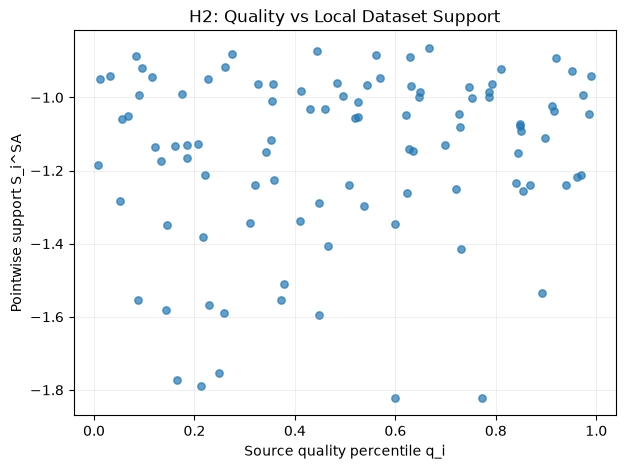

Spearman correlation = 0.0997


In [11]:
plt.figure(
    figsize=(7, 5)
)

plt.scatter(
    pilot["q_i"],
    pilot["SA_support_score"],
    s=28,
    alpha=0.70,
)

plt.xlabel(
    "Source quality percentile q_i"
)

plt.ylabel(
    "Pointwise support S_i^SA"
)

plt.title(
    "H2: Quality vs Local Dataset Support"
)

plt.grid(
    alpha=0.2
)

plt.show()


spearman = (
    pilot[
        [
            "q_i",
            "SA_support_score",
        ]
    ]
    .corr(
        method="spearman"
    )
    .iloc[0, 1]
)


print(
    "Spearman correlation =",
    round(
        float(spearman),
        4,
    ),
)